# NLP Lab07 — Transformer

---

| ส่วน | สไลด์ | งาน | TODO |
|---|---|---|---|
| **1** | ส่วนที่ 1 · Attention Is All You Need | **สร้าง** Transformer เองทีละชิ้นตามเปเปอร์ แล้วฝึก Mini-GPT ภาษาไทย | 1–7 |
| **2** | ส่วนที่ 2 · ตามตำรา | **ใช้** โมเดลสำเร็จรูปสามตระกูล (encoder / decoder) — tokenizer, logits, attention, generate | 8–10 | 
| **3** | ส่วนที่ 3 · ปี 2026 | **อ่าน** config ของ GPT-2, BERT, Qwen3 แล้วคำนวณขนาด KV cache | 11 |
| **4** | ส่วนที่ 4 · การประยุกต์ | **Fine-tune** WangchanBERTa กับ wisesight (ชุดเดียวกับแล็บ 5–6) และ **แปลภาษา** ไทย→อังกฤษ วัดด้วย chrF | 12–15 |

---
# Part0 - Setting

In [1]:
# !pip install -q torch transformers datasets accelerate matplotlib sentencepiece sacremoses scikit-learn sacrebleu
# !pip install tf-keras

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import transformers
from transformers import (AutoConfig, AutoTokenizer, AutoModel, AutoModelForCausalLM,
                          AutoModelForSequenceClassification, pipeline)

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
transformers.logging.set_verbosity_error()   # ซ่อนคำเตือนยาว ๆ ของไลบรารี

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch      :", torch.__version__)
print("Transformers :", transformers.__version__)
print("อุปกรณ์       :", DEVICE)

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch      : 2.14.1+cpu
Transformers : 5.22.1
อุปกรณ์       : cpu


---
# Part 1 — build your Transformer (Mini-GPT)

เราจะสร้าง **decoder-only Transformer** ขนาดเล็ก (สถาปัตยกรรมเดียวกับ GPT-2 แต่เล็กกว่าหลายพันเท่า)
ทีละชิ้นตามลำดับหัวข้อของเปเปอร์ แล้วฝึกเป็นโมเดลภาษาบนคลังข้อความภาษาไทยสังเคราะห์

| ชิ้นส่วน | เปเปอร์ | TODO |
|---|---|---|
| Scaled dot-product attention | §3.2.1 | 1 |
| Multi-head attention | §3.2.2 | 2 |
| Positional encoding | §3.5 | 3 |
| Block (attention + FFN + residual + LayerNorm) | §3.1, §3.3 | 4 |
| Causal mask (decoder) | §3.2.3 | 5 |
| ฝึก + สร้างข้อความ | §5 | 6–7 |

```
token ids ─► Embedding ─► + Positional Encoding ─► [ Transformer Block ] × N ─► LayerNorm ─► Linear ─► logits
                                                     │
                                                     ├─ x = x + MultiHeadAttn(LN(x), causal mask)
                                                     └─ x = x + FFN(LN(x))
```

## 1.1 Scaled Dot-Product Attention

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

- หารด้วย $\sqrt{d_k}$ เพื่อไม่ให้ค่า dot product ใหญ่เกินจน softmax อิ่มตัว (gradient หาย)
- $M$ คือ mask: ตำแหน่งที่ **ห้ามมอง** ใส่ $-\infty$ → หลัง softmax มีน้ำหนักเป็น 0
- ใน Lab นี้ `mask` เป็น boolean: **`True` = มองได้**, `False` = ห้ามมอง (แบบเดียวกับ PyTorch)

### ✏️ TODO 1 — scaled_dot_product_attention

In [4]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)      # (..., T_q, T_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))   # True = มองได้
    weights = F.softmax(scores, dim=-1)
    output = weights @ V                                    # (..., T_q, d_v)
    return output, weights

In [5]:
# 🔍 ตรวจคำตอบ — เทียบกับฟังก์ชันของ PyTorch
torch.manual_seed(0)
Q, K, V = torch.randn(2, 4, 5, 8), torch.randn(2, 4, 5, 8), torch.randn(2, 4, 5, 8)
m = torch.tril(torch.ones(5, 5, dtype=torch.bool))
out, w = scaled_dot_product_attention(Q, K, V, m)
ref = F.scaled_dot_product_attention(Q, K, V, attn_mask=m)
assert torch.allclose(out, ref, atol=1e-5)
assert torch.allclose(w.sum(-1), torch.ones(2, 4, 5))
assert (w[..., 0, 1:] == 0).all(), "token แรกต้องมองไม่เห็นอนาคต"
print("✅ TODO 1 ผ่าน")

✅ TODO 1 ผ่าน


### ตรวจกับตัวอย่างคำนวณมือในสไลด์ 7-1 · 7

สามคำ "แมว กิน ปลา" กับ d_k = 2 — แถวของ "กิน" ต้องได้น้ำหนัก ≈ [0.28, 0.14, 0.58] และผลลัพธ์ ≈ [0.86, 0.72]

In [7]:
Qh = torch.tensor([[1., 0.], [1., 1.], [0., 1.]])     # q ของ แมว, กิน, ปลา
Kh = torch.tensor([[2., 0.], [0., 1.], [1., 2.]])
Vh = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
out_h, w_h = scaled_dot_product_attention(Qh, Kh, Vh)
print("น้ำหนัก (แถว = query):\n", w_h.numpy().round(3))
print("ผลลัพธ์ของ 'กิน':", out_h[1].numpy().round(3))
assert torch.allclose(w_h[1], torch.tensor([0.284, 0.140, 0.576]), atol=1e-3)
assert torch.allclose(out_h[1], torch.tensor([0.860, 0.716]), atol=1e-3)
print("✅ ตรงกับสไลด์")

น้ำหนัก (แถว = query):
 [[0.576 0.14  0.284]
 [0.284 0.14  0.576]
 [0.14  0.284 0.576]]
ผลลัพธ์ของ 'กิน': [0.86  0.716]
✅ ตรงกับสไลด์


## 1.2 Multi-Head Attention

$$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, \dots, \text{head}_h)\,W^O,\qquad
\text{head}_i = \text{Attention}(XW_i^Q,\ XW_i^K,\ XW_i^V)$$

เคล็ดลับการเขียน: ใช้ `Linear(d_model, d_model)` ตัวเดียวสำหรับ Q (และ K, V) แล้ว **แบ่งมิติสุดท้าย** เป็น `h` หัว

`(B, T, d_model)` → `view` → `(B, T, h, d_k)` → `transpose(1, 2)` → `(B, h, T, d_k)`

### ✏️ TODO 2 — คลาส MultiHeadAttention

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, _ = x.shape

        # ฉาย แล้วแบ่งเป็นหัว: (B, T, d_model) -> (B, h, T, d_k)
        def split(t):
            return t.view(B, T, self.h, self.d_k).transpose(1, 2)

        Q, K, V = split(self.W_q(x)), split(self.W_k(x)), split(self.W_v(x))

        out, weights = scaled_dot_product_attention(Q, K, V, mask)   # out: (B, h, T, d_k)
        self.last_attn = weights                                      # (B, h, T, T)

        # รวมหัวกลับ: (B, h, T, d_k) -> (B, T, d_model)
        out = out.transpose(1, 2).contiguous().view(B, T, self.h * self.d_k)
        return self.drop(self.W_o(out))

In [9]:
# 🔍 ตรวจคำตอบ
mha = MultiHeadAttention(d_model=32, n_heads=4, dropout=0.0)
x = torch.randn(3, 7, 32)
y = mha(x, mask=torch.tril(torch.ones(7, 7, dtype=torch.bool)))
assert y.shape == (3, 7, 32)
assert mha.last_attn.shape == (3, 4, 7, 7)
assert sum(p.numel() for p in mha.parameters()) == 4 * (32 * 32 + 32)
# causal: เปลี่ยน token สุดท้าย ต้องไม่กระทบผลลัพธ์ของตำแหน่งก่อนหน้า
x2 = x.clone(); x2[:, -1] += 1.0
y2 = mha(x2, mask=torch.tril(torch.ones(7, 7, dtype=torch.bool)))
assert torch.allclose(y[:, :-1], y2[:, :-1], atol=1e-6)
print("✅ TODO 2 ผ่าน")

✅ TODO 2 ผ่าน


## 1.3 Positional Encoding

Self-attention **ไม่รู้ลำดับคำ** (สลับ token แล้วผลลัพธ์แค่สลับตามกัน — permutation equivariant)
จึงต้องบวกข้อมูลตำแหน่งเข้าไปใน embedding:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right),\qquad
PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

### ✏️ TODO 3 — sinusoidal positional encoding

In [12]:
def sinusoidal_pe(max_len, d_model):
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)        # (max_len, 1)
    two_i = torch.arange(0, d_model, 2, dtype=torch.float32)             # (d_model/2,)
    div_term = torch.exp(-math.log(10000.0) * two_i / d_model)           # = 1 / 10000^(2i/d)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos * div_term)                              # คอลัมน์คู่ -> sin
    pe[:, 1::2] = torch.cos(pos * div_term)                              # คอลัมน์คี่ -> cos
    return pe

✅ TODO 3 ผ่าน


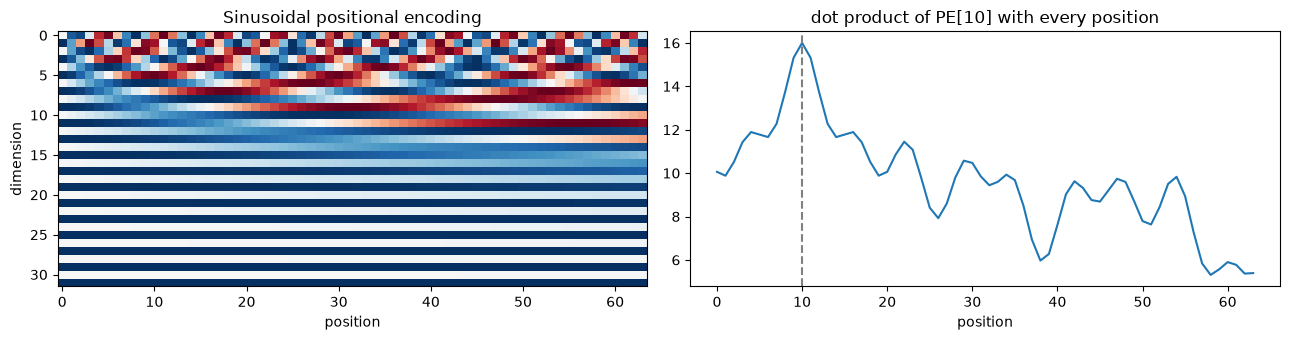

In [13]:
# 🔍 ตรวจคำตอบ + วาดกราฟ
pe = sinusoidal_pe(64, 32)
assert pe.shape == (64, 32)
assert torch.allclose(pe[0, 0::2], torch.zeros(16)) and torch.allclose(pe[0, 1::2], torch.ones(16))
assert abs(pe[3, 4].item() - math.sin(3 / 10000 ** (4 / 32))) < 1e-6
print("✅ TODO 3 ผ่าน")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].imshow(pe.T, cmap="RdBu", aspect="auto"); ax[0].set_xlabel("position"); ax[0].set_ylabel("dimension")
ax[0].set_title("Sinusoidal positional encoding")
sim = (pe @ pe.T)
ax[1].plot(sim[10].numpy()); ax[1].axvline(10, ls="--", c="gray")
ax[1].set_title("dot product of PE[10] with every position"); ax[1].set_xlabel("position")
plt.tight_layout(); plt.show()

**สังเกต:** กราฟขวามียอดที่ตำแหน่ง 10 และลดลงเมื่อห่างออกไป — dot product ของ PE จึงเข้ารหัส
**ระยะห่างสัมพัทธ์** ได้ ซึ่ง attention (ที่ใช้ dot product) นำไปใช้ต่อได้ทันที

## 1.4 Transformer Block (Pre-LayerNorm)

```
x ──► LN ──► MultiHeadAttn ──► (+) ──► LN ──► FFN ──► (+) ──►
 └─────────────────────────────┘ └────────────────────┘
          residual                      residual
```

- **FFN** = `Linear(d, 4d) → GELU → Linear(4d, d) → Dropout` ทำงานแยกทีละตำแหน่ง
- **Pre-LN** (LN ก่อน sublayer) ฝึกง่ายกว่าแบบดั้งเดิม (Post-LN) และไม่ต้องใช้ warmup นาน — GPT-2 ก็ใช้แบบนี้

> 📖 **หมายเหตุ — pre-norm (ตำรา) vs post-norm (เปเปอร์)**
> เปเปอร์ปี 2017 ใช้ **post-norm**: `x = LayerNorm(x + Sublayer(x))` (§3.1)
> แล็บนี้ใช้ **pre-norm** ตาม SLP3 eq 8.38–8.39 (หน้า 186): `x = x + Sublayer(LayerNorm(x))` และมี LayerNorm ปิดท้ายอีกตัว (`ln_f` ใน MiniGPT)
> ทางลัด (residual) จึงไหลตรงจากล่างถึงบนโดยไม่ถูก LayerNorm คั่น — ฝึกโมเดลลึกได้เสถียรกว่า และเป็นแบบที่ LLM แทบทุกตัวในปี 2026 ใช้ (สไลด์ 7-1 · 11, 16)
> FFN ในแล็บใช้ GELU ส่วนเปเปอร์ใช้ ReLU

### ✏️ TODO 4 — คลาส TransformerBlock

In [14]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, mask=None):
        x = x + self.attn(self.ln1(x), mask)   # sublayer 1: attention + residual
        x = x + self.ffn(self.ln2(x))          # sublayer 2: FFN + residual
        return x

In [15]:
# 🔍 ตรวจคำตอบ
blk = TransformerBlock(32, 4, dropout=0.0)
assert blk(torch.randn(2, 6, 32)).shape == (2, 6, 32)
assert sum(p.numel() for p in blk.parameters()) == 12_704
print("✅ TODO 4 ผ่าน")

✅ TODO 4 ผ่าน


## 1.5 Causal Mask และ Mini-GPT

โมเดลภาษาทำนายคำถัดไป จึง **ห้ามแอบดูอนาคต** — ตำแหน่ง $t$ มองได้แค่ $1 \dots t$

$$M = \begin{bmatrix} 1&0&0&0\\ 1&1&0&0\\ 1&1&1&0\\ 1&1&1&1 \end{bmatrix}$$

ข้อดีใหญ่เหนือ RNN: ฝึกได้ **ทุกตำแหน่งพร้อมกัน** ในการ forward ครั้งเดียว (ขนานตามแกนเวลา)

### ✏️ TODO 5 — causal_mask

In [16]:
def causal_mask(T, device=None):
    return torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))

In [17]:
# 🔍 ตรวจคำตอบ
assert causal_mask(4).tolist() == [[True, False, False, False], [True, True, False, False],
                                   [True, True, True, False], [True, True, True, True]]
print("✅ TODO 5 ผ่าน")

✅ TODO 5 ผ่าน


ประกอบทุกชิ้นเข้าด้วยกันเป็น **Mini-GPT** (เซลล์นี้ให้มาแล้ว อ่านให้เข้าใจทุกบรรทัด)

In [18]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=3, block_size=32, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.register_buffer("pe", sinusoidal_pe(block_size, d_model))
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight          # weight tying (เหมือน GPT-2)
        self.d_model = d_model

    def forward(self, idx):
        B, T = idx.shape
        assert T <= self.block_size
        x = self.tok_emb(idx) * math.sqrt(self.d_model) + self.pe[:T]
        x = self.drop(x)
        mask = causal_mask(T, idx.device)
        for blk in self.blocks:
            x = blk(x, mask)
        return self.head(self.ln_f(x))                   # (B, T, V)

## 1.6 ข้อมูล — ประโยคภาษาไทยที่มี **ลักษณนาม**

เราออกแบบคลังข้อความให้มีปรากฏการณ์ทางภาษาที่ **n-gram ทำไม่ได้แต่ attention ทำได้**:
ลักษณนามต้องสอดคล้องกับคำนามที่อยู่ **ห่างออกไปหลายคำ**

| ประโยค | คำนาม → ลักษณนาม |
|---|---|
| ฉัน ซื้อ **หนังสือ** ใหม่ สีแดง สาม **เล่ม** ที่ ตลาด | หนังสือ → เล่ม |
| แม่ เห็น **แมว** สีฟ้า สอง **ตัว** | แมว → ตัว |
| พ่อ ขาย **รถ** เก่า หนึ่ง **คัน** เมื่อวาน | รถ → คัน |

คำก่อนลักษณนามเป็น **ตัวเลขเสมอ** — bigram/trigram ที่มองแค่ 1–2 คำก่อนหน้าจึงเดาไม่ได้ว่าลักษณนามคืออะไร

In [19]:
SUBJ = ["ฉัน", "เขา", "เธอ", "แม่", "พ่อ", "เพื่อน", "อาจารย์", "นักเรียน", "น้อง", "ลุง"]
VERB = ["ซื้อ", "เห็น", "ชอบ", "ขาย", "อยาก ได้", "ให้", "เก็บ", "หา"]
NOUN_CLF = [("แมว", "ตัว"), ("สุนัข", "ตัว"), ("ปลา", "ตัว"), ("เสื้อ", "ตัว"),
            ("หนังสือ", "เล่ม"), ("สมุด", "เล่ม"), ("รถ", "คัน"), ("ร่ม", "คัน"),
            ("บ้าน", "หลัง"), ("ปากกา", "ด้าม"), ("ต้นไม้", "ต้น"), ("ดินสอ", "แท่ง"),
            ("แก้ว", "ใบ"), ("กระเป๋า", "ใบ"), ("จาน", "ใบ"), ("ช้อน", "คัน")]
ADJ = ["ใหม่", "เก่า", "สวย", "ใหญ่", "เล็ก", "สีแดง", "สีฟ้า", "ราคา ถูก", "ของ ฉัน"]
NUM = ["หนึ่ง", "สอง", "สาม", "สี่", "ห้า", "หก"]
PLACE = ["ที่ ตลาด", "ที่ ร้าน", "ใน เมือง", "ที่ บ้าน", "ที่ โรงเรียน"]
TIME = ["เมื่อวาน", "วันนี้", "ตอน เช้า", "เมื่อ สัปดาห์ ก่อน"]
CLFS = sorted({c for _, c in NOUN_CLF})


def noun_phrase(rng):
    n, c = rng.choice(NOUN_CLF)
    adjs = rng.sample(ADJ, rng.randint(0, 3))
    return [n] + " ".join(adjs).split() + [rng.choice(NUM), c]


def make_sentence(rng):
    s = rng.choice(SUBJ).split() + rng.choice(VERB).split() + noun_phrase(rng)
    if rng.random() < 0.3:
        s += ["และ"] + noun_phrase(rng)
    if rng.random() < 0.5:
        s += rng.choice(PLACE).split()
    if rng.random() < 0.5:
        s += rng.choice(TIME).split()
    return s


rng = random.Random(SEED)
sents = [make_sentence(rng) for _ in range(12_000)]
train_sents, val_sents = sents[:11_000], sents[11_000:]
for s in sents[:5]:
    print(" ".join(s))

เขา ซื้อ บ้าน ใหญ่ สอง หลัง
เขา เก็บ สุนัข หนึ่ง ตัว และ แมว ของ ฉัน สี่ ตัว ที่ โรงเรียน เมื่อวาน
เธอ เก็บ ต้นไม้ สวย ใหญ่ สาม ต้น และ แก้ว สาม ใบ
ฉัน หา เสื้อ เก่า เล็ก สีฟ้า หก ตัว
เขา ซื้อ ร่ม เก่า ใหญ่ หนึ่ง คัน ใน เมือง ตอน เช้า


In [20]:
EOS = "</s>"
itos = [EOS] + sorted({w for s in sents for w in s})
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)


def encode_corpus(ss):
    return torch.tensor([stoi[w] for s in ss for w in s + [EOS]], dtype=torch.long)


train_ids, val_ids = encode_corpus(train_sents), encode_corpus(val_sents)
print(f"vocab = {V} คำ | train = {len(train_ids):,} tokens | val = {len(val_ids):,} tokens")

BLOCK = 32


def get_batch(data, batch_size=64, block=BLOCK):
    """สุ่มหน้าต่างยาว block จากสายโทเคน คืน x และ y ที่เลื่อนไป 1 ตำแหน่ง"""
    ix = torch.randint(len(data) - block - 1, (batch_size,))
    x = torch.stack([data[i:i + block] for i in ix])
    y = torch.stack([data[i + 1:i + block + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)


xb, yb = get_batch(train_ids, 2)
print("x:", " ".join(itos[i] for i in xb[0][:12].tolist()))
print("y:", " ".join(itos[i] for i in yb[0][:12].tolist()))

vocab = 74 คำ | train = 127,846 tokens | val = 11,646 tokens
x: ที่ โรงเรียน วันนี้ </s> นักเรียน อยาก ได้ แมว ราคา ถูก เก่า หก
y: โรงเรียน วันนี้ </s> นักเรียน อยาก ได้ แมว ราคา ถูก เก่า หก ตัว


## 1.7 ฝึกโมเดล

$$\mathcal{L} = -\frac{1}{BT}\sum_{b,t} \log P(y_{b,t} \mid x_{b,\le t}) \qquad \text{Perplexity} = e^{\mathcal{L}}$$

**จุดที่มักพลาด:** `F.cross_entropy` ต้องการ logits รูป `(N, V)` และเป้ารูป `(N,)` → ต้อง `view(-1, V)` ก่อน

📖 เปเปอร์ใช้ Adam + warmup 4,000 steps (สไลด์ 7-1 · 12) — Mini-GPT เล็กมากจึงใช้ AdamW lr คงที่ก็พอ

### ✏️ TODO 6 — training loop ของ Mini-GPT

In [23]:
def train_lm(model, steps=1000, lr=3e-3, eval_every=250, clip=1.0):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    history = []
    model.train()
    for step in range(1, steps + 1):
        x, y = get_batch(train_ids)
        logits = model(x)                                              # (B, T, V)
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()

        if step % eval_every == 0 or step == steps:
            tr = estimate_loss(model, train_ids)
            va = estimate_loss(model, val_ids)
            history.append((step, tr, va))
            print(f"step {step:5d} | train {tr:.3f} (ppl {math.exp(tr):.2f}) "
                  f"| val {va:.3f} (ppl {math.exp(va):.2f})")
    return history

Mini-GPT: 605 K พารามิเตอร์
step   250 | train 2.033 (ppl 7.64) | val 2.037 (ppl 7.67)
step   500 | train 1.892 (ppl 6.63) | val 1.901 (ppl 6.69)
step   750 | train 1.833 (ppl 6.25) | val 1.834 (ppl 6.26)
step  1000 | train 1.806 (ppl 6.09) | val 1.815 (ppl 6.14)


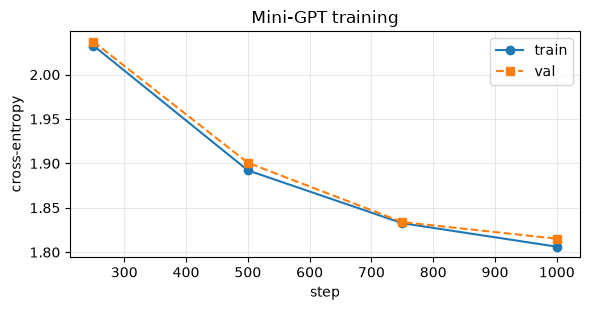

✅ TODO 6 ผ่าน


In [24]:
set_seed()
model = MiniGPT(V, d_model=128, n_heads=4, n_layers=3, block_size=BLOCK).to(DEVICE)
print(f"Mini-GPT: {sum(p.numel() for p in model.parameters()) / 1e3:.0f} K พารามิเตอร์")
history = train_lm(model, steps=1000)

steps_, tr_, va_ = zip(*history)
plt.figure(figsize=(6, 3.2))
plt.plot(steps_, tr_, "o-", label="train"); plt.plot(steps_, va_, "s--", label="val")
plt.xlabel("step"); plt.ylabel("cross-entropy"); plt.legend(); plt.grid(alpha=.3)
plt.title("Mini-GPT training"); plt.tight_layout(); plt.show()

# 🔍 ตรวจคำตอบ
assert history[-1][2] < 1.9, "val loss ควรต่ำกว่า 1.9 — ตรวจ training loop อีกครั้ง"
print("✅ TODO 6 ผ่าน")

### ✏️ TODO 7 — สร้างข้อความด้วย Mini-GPT (temperature + top-k)

📖 สไลด์ 7-1 · 19 · SLP3 §8.6 หน้า 190–192
- หาร logits ด้วย `temperature` ก่อน softmax ( < 1 คมขึ้น, > 1 แบนลง)
- `top_k`: เก็บเฉพาะ k คำที่ logit สูงสุด คำอื่นตั้งเป็น −∞ แล้วค่อยสุ่ม

In [26]:
@torch.no_grad()
def generate(model, prefix, max_new_tokens=20, temperature=1.0, top_k=None, greedy=False):
    model.eval()
    device = next(model.parameters()).device
    words = prefix.split()
    ids = torch.tensor([[stoi[EOS]] + [stoi[w] for w in words]], device=device)

    for _ in range(max_new_tokens):
        ctx = ids[:, -model.block_size:]
        logits = model(ctx)[0, -1] / temperature                  # (V,)

        if top_k is not None:
            k = min(top_k, logits.size(-1))
            kth = torch.topk(logits, k).values[-1]                # ค่าอันดับที่ k
            logits = logits.masked_fill(logits < kth, float("-inf"))

        if greedy:
            nxt = logits.argmax(-1, keepdim=True)                 # (1,)
        else:
            probs = F.softmax(logits, dim=-1)
            nxt = torch.multinomial(probs, 1)                     # (1,)

        if nxt.item() == stoi[EOS]:
            break
        words.append(itos[nxt.item()])
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)

    return " ".join(words)

In [27]:
torch.manual_seed(1)
for p in ["แม่ ซื้อ", "อาจารย์ เห็น หนังสือ", "พ่อ ขาย รถ เก่า สีแดง", "เพื่อน ชอบ"]:
    print(generate(model, p, temperature=0.8, top_k=10))

# 🔍 ตรวจคำตอบ
out = generate(model, "ฉัน ซื้อ บ้าน ใหม่ สอง", greedy=True)
print("\ngreedy:", out)
assert out.split()[5] == "หลัง", "บ้าน ต้องใช้ลักษณนาม หลัง"
print("✅ TODO 7 ผ่าน")

# top_k = 1 ต้องเหมือน greedy เสมอ
torch.manual_seed(0)
assert generate(model, "แม่ ซื้อ", top_k=1) == generate(model, "แม่ ซื้อ", greedy=True)
print("✅ top_k = 1 ให้ผลเท่ากับ greedy")

แม่ ซื้อ แก้ว ใหม่ หนึ่ง ใบ ที่ ตลาด
อาจารย์ เห็น หนังสือ สีฟ้า เก่า สาม เล่ม ที่ โรงเรียน วันนี้
พ่อ ขาย รถ เก่า สีแดง สาม คัน ที่ ตลาด วันนี้
เพื่อน ชอบ แมว สวย ราคา ถูก สาม ตัว และ ร่ม ของ ฉัน หก คัน

greedy: ฉัน ซื้อ บ้าน ใหม่ สอง หลัง และ ปากกา ของ ฉัน สี่ หลัง ที่ โรงเรียน
✅ TODO 7 ผ่าน
✅ top_k = 1 ให้ผลเท่ากับ greedy


## 1.8 การทดลอง — Transformer เรียนรู้ความสอดคล้องของลักษณนามได้จริงไหม?

เราจะวัด **ความแม่นยำในการทำนายลักษณนาม** บนประโยค validation:
ทุกครั้งที่คำถัดไปเป็นลักษณนาม ให้ดูว่า argmax ของโมเดลตรงไหม แล้วเทียบกับ **baseline n-gram**
ที่ทำนายลักษณนามที่พบบ่อยที่สุดตามบริบท 2 คำก่อนหน้า (trigram)

In [28]:
@torch.no_grad()
def classifier_accuracy(model, sents, max_sents=500):
    model.eval()
    correct = total = 0
    by_gap = Counter(); by_gap_ok = Counter()
    for s in sents[:max_sents]:
        ids = torch.tensor([[stoi[EOS]] + [stoi[w] for w in s]], device=DEVICE)[:, :model.block_size]
        pred = model(ids)[0].argmax(-1).tolist()          # pred[t] = ทายคำที่ t+1 (นับรวม </s> นำหน้า)
        last_noun = None
        for t, w in enumerate(s[:model.block_size - 1]):
            if w in {n for n, _ in NOUN_CLF}:
                last_noun = t
            if w in CLFS and t > 0 and s[t - 1] in NUM:
                gap = t - last_noun
                ok = itos[pred[t]] == w
                correct += ok; total += 1
                by_gap[gap] += 1; by_gap_ok[gap] += ok
    return correct / total, {g: by_gap_ok[g] / by_gap[g] for g in sorted(by_gap)}


def trigram_classifier_accuracy(train, test):
    tri = Counter()
    for s in train:
        for a, b, c in zip(s, s[1:], s[2:]):
            if c in CLFS and b in NUM:
                tri[(a, b, c)] += 1
    best = {}
    for (a, b, c), n in tri.items():
        if n > best.get((a, b), ("", 0))[1]:
            best[(a, b)] = (c, n)
    ok = tot = 0
    for s in test:
        for a, b, c in zip(s, s[1:], s[2:]):
            if c in CLFS and b in NUM:
                ok += best.get((a, b), ("",))[0] == c; tot += 1
    return ok / tot


acc, by_gap = classifier_accuracy(model, val_sents)
tri_acc = trigram_classifier_accuracy(train_sents, val_sents)
print(f"Trigram baseline : {tri_acc:.1%}")
print(f"Mini-GPT         : {acc:.1%}")
print("\nความแม่นยำ แยกตามระยะห่าง คำนาม → ลักษณนาม")
for g, a in by_gap.items():
    print(f"  ระยะ {g} คำ : {a:.1%}")

Trigram baseline : 40.6%
Mini-GPT         : 100.0%

ความแม่นยำ แยกตามระยะห่าง คำนาม → ลักษณนาม
  ระยะ 2 คำ : 100.0%
  ระยะ 3 คำ : 100.0%
  ระยะ 4 คำ : 100.0%
  ระยะ 5 คำ : 100.0%
  ระยะ 6 คำ : 100.0%
  ระยะ 7 คำ : 100.0%


### ดู attention ของ Mini-GPT ตอนทำนายลักษณนาม

ตำแหน่งของตัวเลข (ซึ่งเป็นตำแหน่งที่ต้องทำนายลักษณนาม) ควรส่งความสนใจกลับไปที่ **คำนาม** ที่อยู่ห่างออกไป

ทำนายคำถัดไป: เล่ม


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarning: Glyph 3593 (\N{THAI CHARACTER CHO CHING}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarning: Glyph 3595 (\N{THAI CHARACTER SO SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\1610596018.py:19: UserWarni

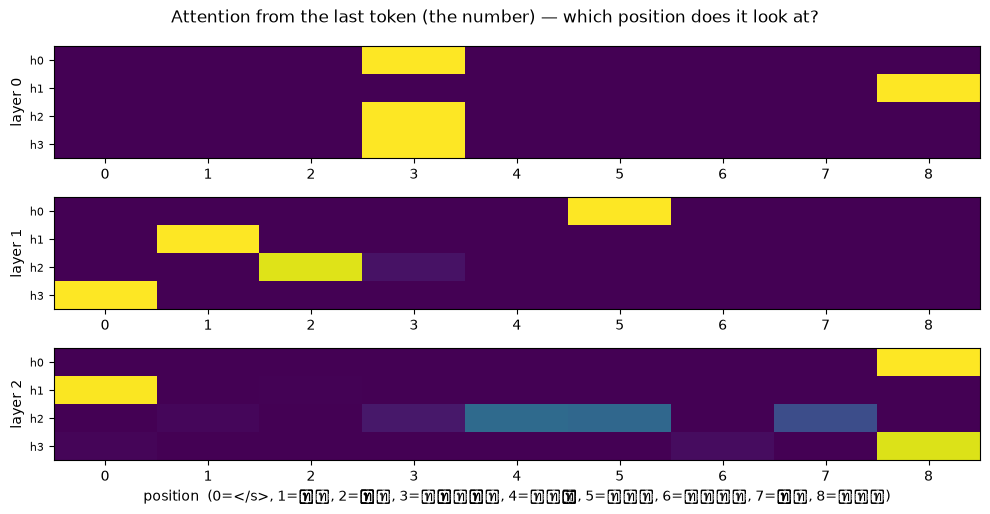

ตำแหน่งที่ 3 คือคำนาม 'หนังสือ'


In [29]:
s = "ฉัน ซื้อ หนังสือ ใหม่ สวย ราคา ถูก สาม".split()
ids = torch.tensor([[stoi[EOS]] + [stoi[w] for w in s]], device=DEVICE)
model.eval()
with torch.no_grad():
    nxt = itos[model(ids)[0, -1].argmax().item()]
print("ทำนายคำถัดไป:", nxt)

labels = ["</s>"] + s
n_layers, n_heads = len(model.blocks), model.blocks[0].attn.h
fig, axes = plt.subplots(n_layers, 1, figsize=(10, 1.4 * n_layers + 1))
for L, ax in enumerate(axes):
    A = model.blocks[L].attn.last_attn[0, :, -1, :].cpu().numpy()   # (heads, T) แถวของคำสุดท้าย
    ax.imshow(A, cmap="viridis", aspect="auto", vmin=0, vmax=1)
    ax.set_yticks(range(n_heads)); ax.set_yticklabels([f"h{h}" for h in range(n_heads)], fontsize=8)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels([f"{i}" for i in range(len(labels))])
    ax.set_ylabel(f"layer {L}")
axes[-1].set_xlabel("position  (" + ", ".join(f"{i}={w}" for i, w in enumerate(labels)) + ")")
plt.suptitle("Attention from the last token (the number) — which position does it look at?")
plt.tight_layout(); plt.show()
print("ตำแหน่งที่ 3 คือคำนาม 'หนังสือ'")

**คำถามชวนคิด:** มีหัวไหนที่ให้น้ำหนักมากกับตำแหน่ง 3 (คำนาม) บ้าง? หัวนั้นอยู่ชั้นไหน?
ถ้าไม่มีหัวใดชี้ไปที่คำนามโดยตรง ข้อมูลของคำนามอาจถูก "ส่งต่อ" ผ่าน residual stream
ของตำแหน่งอื่นในชั้นก่อนหน้า — ลองเปลี่ยนประโยคแล้วดูอีกครั้ง

---
# Part 2 Pretrained Transformers

Transformer ที่ใช้กันจริงแบ่งได้ 3 ตระกูลตามส่วนที่เก็บไว้จากสถาปัตยกรรมต้นฉบับ (Vaswani et al., 2017):

| ตระกูล | ตัวอย่าง | attention | ฝึกด้วย | เหมาะกับ |
|---|---|---|---|---|
| **Encoder-only** | BERT, RoBERTa, WangchanBERTa | สองทิศทาง (เห็นทั้งประโยค) | Masked LM | จำแนกข้อความ, NER, ค้นคืน |
| **Decoder-only** | GPT-2, Llama, Typhoon | ทิศทางเดียว (causal) | ทำนายคำถัดไป | สร้างข้อความ, แชต |
| **Encoder–Decoder** | T5, BART, mT5 | encoder สองทิศ + cross-attention | span corruption / denoising | แปลภาษา, สรุปความ |

ส่วนที่ 1 เราสร้าง decoder เองจากศูนย์ ส่วนนี้ใช้ของจริงที่ฝึกบนข้อความหลายพันล้านคำ
ไลบรารี 🤗 `transformers` ให้เราโหลดโมเดลเหล่านี้ได้ในบรรทัดเดียว (encoder–decoder จะได้ใช้ในส่วนที่ 4.6)

## 2.1 วิธีที่ง่ายที่สุด — `pipeline`

`pipeline` รวม 3 ขั้นตอนไว้ในคำสั่งเดียว: **tokenize → model → post-process**

In [30]:
clf = pipeline("sentiment-analysis",
               model="distilbert-base-uncased-finetuned-sst-2-english", device=DEVICE)
clf(["I really enjoyed this NLP course!",
     "The lecture was too long and quite boring."])

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packag

[{'label': 'POSITIVE', 'score': 0.9998608827590942},
 {'label': 'NEGATIVE', 'score': 0.9996562004089355}]

In [31]:
fill = pipeline("fill-mask", model="distilbert-base-uncased", device=DEVICE)
for r in fill("The capital of Thailand is [MASK]."):
    print(f"{r['token_str']:>12s}  {r['score']:.3f}")

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1153.29it/s]


     bangkok  0.993
    thailand  0.002
         mai  0.001
        siam  0.000
        thai  0.000


In [32]:
gen = pipeline("text-generation", model="distilgpt2", device=DEVICE)
out = gen("Natural language processing is", max_new_tokens=30, do_sample=False,
          pad_token_id=50256)
print(out[0]["generated_text"])

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 76/76 [00:00<00:00, 351.90it/s]


Natural language processing is a common feature of the language processing process.























**สังเกต:** โมเดลทั้งสามเป็น Transformer เหมือนกัน แต่ทำงานต่างกัน
- `fill-mask` ใช้ encoder ที่มองเห็น **ทั้งซ้ายและขวา** ของ `[MASK]`
- `text-generation` ใช้ decoder ที่มองเห็น **เฉพาะคำทางซ้าย** แล้วเดาคำถัดไปทีละคำ

## 2.2 เปิดกล่อง — Tokenizer

Transformer ไม่ได้รับ "คำ" แต่รับ **ID ของ subword** (WordPiece สำหรับ BERT, BPE สำหรับ GPT-2,
SentencePiece สำหรับ XLM-R / WangchanBERTa) — ทบทวนเรื่อง BPE จากสัปดาห์ที่ 1

In [33]:
CLF_NAME = "distilbert-base-uncased-finetuned-sst-2-english"
tok = AutoTokenizer.from_pretrained(CLF_NAME)

enc = tok("Transformers are unbelievably powerful!")
print("input_ids     :", enc["input_ids"])
print("tokens        :", tok.convert_ids_to_tokens(enc["input_ids"]))
print("attention_mask:", enc["attention_mask"])
print("ขนาด vocab     :", tok.vocab_size)

input_ids     : [101, 19081, 2024, 4895, 8671, 2666, 3567, 6321, 3928, 999, 102]
tokens        : ['[CLS]', 'transformers', 'are', 'un', '##bel', '##ie', '##va', '##bly', 'powerful', '!', '[SEP]']
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
ขนาด vocab     : 30522


### ภาษาไทยล่ะ? — tokenizer ต่างกันมาก

📖 สไลด์ 7-1 · 18 และ 28 · ทบทวน BPE / SentencePiece จากสัปดาห์ที่ 1–2

In [34]:
th = "ฉันชอบเรียนการประมวลผลภาษาธรรมชาติ"
TOK_NAMES = ["distilbert-base-uncased-finetuned-sst-2-english",   # WordPiece อังกฤษ
             "gpt2",                                              # byte-level BPE อังกฤษ
             "xlm-roberta-base",                                  # SentencePiece หลายภาษา
             "airesearch/wangchanberta-base-att-spm-uncased"]     # SentencePiece ไทย
tok_counts = {}
for name in TOK_NAMES:
    t = AutoTokenizer.from_pretrained(name)
    pieces = t.tokenize(th)
    tok_counts[name] = len(pieces)
    print(f"{name:<48s} {len(pieces):>3d} โทเคน  {pieces[:10]}")
tok_xlmr = AutoTokenizer.from_pretrained("xlm-roberta-base")

distilbert-base-uncased-finetuned-sst-2-english    1 โทเคน  ['[UNK]']


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


gpt2                                              68 โทเคน  ['à¸', 'ī', 'à¸', '±', 'à¸', 'Ļ', 'à¸', 'Ĭ', 'à¸', 'Ń']


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--xlm-roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


xlm-roberta-base                                   9 โทเคน  ['▁ฉัน', 'ชอบ', 'เรียน', 'การ', 'ประ', 'มวล', 'ผล', 'ภาษา', 'ธรรมชาติ']


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--airesearch--wangchanberta-base-att-spm-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


airesearch/wangchanberta-base-att-spm-uncased      6 โทเคน  ['▁ฉันชอบ', 'เรียน', 'การ', 'ประมวลผล', 'ภาษา', 'ธรรมชาติ']


**คำถามชวนคิด:** ประโยคเดียวกันกลายเป็นกี่โทเคนในแต่ละ tokenizer?
- BERT อังกฤษแทบทุกตัวกลายเป็น `[UNK]` → ไม่มีข้อมูลเหลือให้โมเดล
- GPT-2 ตัดเป็น **byte** (อักษรไทยหนึ่งตัว = 3 ไบต์ใน UTF-8) จำนวนโทเคนจึงพองหลายเท่า → ช้า แพง และ context เต็มเร็ว
- WangchanBERTa ใช้ SentencePiece ที่เรียนจากข้อความไทย จึงได้ชิ้นที่มีความหมายและสั้นที่สุด — เราจะใช้มันในส่วนที่ 4

## 2.3 เปิดกล่อง — Model และ logits

`AutoModelForSequenceClassification` = **Transformer encoder + classification head** (Linear บน `[CLS]`)
ผลลัพธ์คือ **logits** (ยังไม่ผ่าน softmax)

In [35]:
clf_model = AutoModelForSequenceClassification.from_pretrained(
    CLF_NAME, attn_implementation="eager").to(DEVICE).eval()   # eager = คืนค่า attention ได้ (ใช้ใน 2.4)

cfg = clf_model.config
print("จำนวนชั้น (n_layers) :", cfg.n_layers)
print("จำนวนหัว (n_heads)   :", cfg.n_heads)
print("d_model (dim)       :", cfg.dim)
print("d_ff (hidden_dim)   :", cfg.hidden_dim)
print("labels              :", cfg.id2label)
print(f"จำนวนพารามิเตอร์      : {sum(p.numel() for p in clf_model.parameters()) / 1e6:.1f} M")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1528.08it/s]

จำนวนชั้น (n_layers) : 6
จำนวนหัว (n_heads)   : 12
d_model (dim)       : 768
d_ff (hidden_dim)   : 3072
labels              : {0: 'NEGATIVE', 1: 'POSITIVE'}
จำนวนพารามิเตอร์      : 67.0 M


### ✏️ TODO 8 — ทำนายความรู้สึกเองโดยไม่ใช้ `pipeline`

In [36]:
@torch.no_grad()
def predict_sentiment(texts, model=clf_model, tokenizer=tok):
    enc = tokenizer(texts, padding=True, truncation=True, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    logits = model(**enc).logits                      # (B, num_labels)
    probs = F.softmax(logits, dim=-1)
    top_p, top_i = probs.max(dim=-1)                  # ความน่าจะเป็นสูงสุด + index
    return [(model.config.id2label[i.item()], p.item()) for p, i in zip(top_p, top_i)]

In [37]:
# 🔍 ตรวจคำตอบ — ต้องได้ผลตรงกับ pipeline
texts = ["I really enjoyed this NLP course!",
         "The lecture was too long and quite boring.",
         "Not bad at all."]
mine = predict_sentiment(texts)
ref = clf(texts)
for t, m, r in zip(texts, mine, ref):
    print(f"{m[0]:>8s} {m[1]:.4f} | pipeline: {r['label']:>8s} {r['score']:.4f} | {t}")
    assert m[0] == r["label"] and abs(m[1] - r["score"]) < 1e-3
print("✅ TODO 8 ผ่าน")

POSITIVE 0.9999 | pipeline: POSITIVE 0.9999 | I really enjoyed this NLP course!
NEGATIVE 0.9997 | pipeline: NEGATIVE 0.9997 | The lecture was too long and quite boring.
POSITIVE 0.9993 | pipeline: POSITIVE 0.9993 | Not bad at all.
✅ TODO 8 ผ่าน


## 2.4 ดู Attention ของ BERT

ใส่ `output_attentions=True` แล้วโมเดลจะคืน attention ทุกชั้น เป็น tuple ยาว `n_layers`
แต่ละตัวมีรูป `(B, n_heads, T, T)` — แถว *i* คือการกระจายความสนใจของ token *i* ไปยังทุก token

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

📖 สไลด์ 7-1 · 21 (มองข้างใน) — ข้อควรระวัง: น้ำหนัก attention สูงไม่ได้แปลว่าเป็น "เหตุผล" ของคำตอบเสมอไป

### ✏️ TODO 9 — ดึง attention matrix ของชั้นและหัวที่ต้องการ

In [41]:
@torch.no_grad()
def get_attention(text, layer, head, model=clf_model, tokenizer=tok):
    enc = tokenizer(text, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    out = model(**enc, output_attentions=True)
    A = out.attentions[layer][0, head]                       # (T, T)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    return tokens, A.cpu().numpy()

✅ TODO 9 ผ่าน


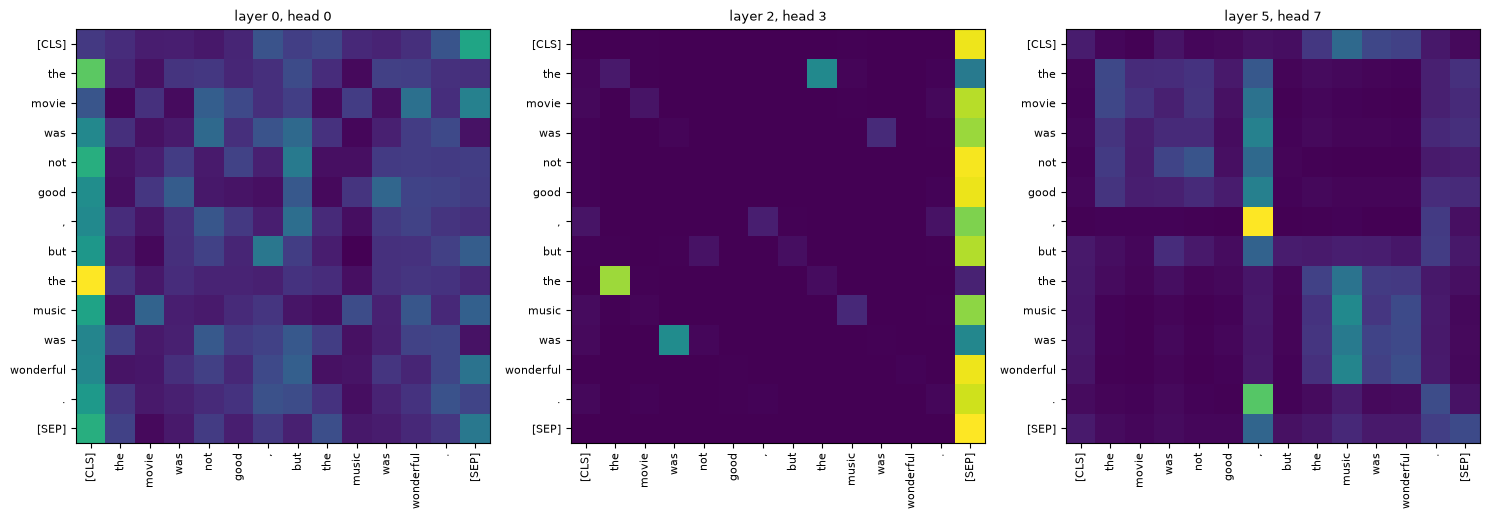

In [42]:
# 🔍 ตรวจคำตอบ + วาดกราฟ
sent = "The movie was not good, but the music was wonderful."
tokens, A = get_attention(sent, layer=0, head=0)
assert A.shape == (len(tokens), len(tokens))
assert np.allclose(A.sum(-1), 1.0, atol=1e-4), "แต่ละแถวของ attention ต้องรวมได้ 1"
print("✅ TODO 9 ผ่าน")


def plot_attn(tokens, A, title="", ax=None):
    ax = ax or plt.gca()
    ax.imshow(A, cmap="viridis")
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=8)
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=8)
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (L, H) in zip(axes, [(0, 0), (2, 3), (5, 7)]):
    plot_attn(*get_attention(sent, L, H), title=f"layer {L}, head {H}", ax=ax)
plt.tight_layout(); plt.show()

**สังเกต:** หัวแต่ละหัวเรียนรู้รูปแบบต่างกัน — บางหัวมองคำข้างเคียง บางหัวมอง `[SEP]`
(ใช้เป็น "ที่ทิ้ง" ความสนใจเมื่อไม่มีอะไรน่าสนใจ) บางหัวจับคู่คำที่สัมพันธ์กันทางไวยากรณ์
นี่คือเหตุผลที่ต้องมี **หลายหัว** — แต่ละหัวเป็นมุมมองหนึ่งต่อประโยค

## 2.5 Decoder-only — สร้างข้อความทีละ token

GPT-2 เป็น **causal LM**: $P(w_1 \dots w_n) = \prod_t P(w_t \mid w_{<t})$
`model.generate()` ซ่อนลูปไว้ข้างใน — เราจะเขียนลูปนั้นเอง

In [43]:
GPT_NAME = "distilgpt2"
gpt_tok = AutoTokenizer.from_pretrained(GPT_NAME)
gpt = AutoModelForCausalLM.from_pretrained(GPT_NAME).to(DEVICE).eval()
print(f"{GPT_NAME}: {sum(p.numel() for p in gpt.parameters()) / 1e6:.1f} M พารามิเตอร์, "
      f"{gpt.config.n_layer} ชั้น, {gpt.config.n_head} หัว, context {gpt.config.n_positions} tokens")

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 263.04it/s]

distilgpt2: 81.9 M พารามิเตอร์, 6 ชั้น, 12 หัว, context 1024 tokens


### ✏️ TODO 10 — greedy decoding ด้วยมือ

In [44]:
@torch.no_grad()
def greedy_generate(prompt, max_new_tokens=20, model=gpt, tokenizer=gpt_tok):
    ids = tokenizer(prompt, return_tensors="pt").input_ids.to(DEVICE)   # (1, T)
    for _ in range(max_new_tokens):
        logits = model(ids).logits                                      # (1, T, V)
        next_id = logits[:, -1, :].argmax(dim=-1, keepdim=True)         # (1, 1)
        ids = torch.cat([ids, next_id], dim=1)
        if next_id.item() == tokenizer.eos_token_id:
            break
    return tokenizer.decode(ids[0])

In [45]:
# 🔍 ตรวจคำตอบ — ต้องตรงกับ model.generate(do_sample=False) ทุกตัวอักษร
prompt = "The Transformer architecture"
mine = greedy_generate(prompt, max_new_tokens=20)
ids = gpt_tok(prompt, return_tensors="pt").input_ids.to(DEVICE)
ref = gpt_tok.decode(gpt.generate(ids, max_new_tokens=20, do_sample=False,
                                  pad_token_id=gpt_tok.eos_token_id)[0])
print("ของเรา  :", mine)
print("generate:", ref)
assert mine == ref
print("✅ TODO 10 ผ่าน")

ของเรา  : The Transformer architecture is a new concept that has been developed by the company, and is designed to be used in the
generate: The Transformer architecture is a new concept that has been developed by the company, and is designed to be used in the
✅ TODO 10 ผ่าน


### Sampling — ทำให้ข้อความหลากหลายขึ้น

greedy มักวนซ้ำ จึงนิยม **สุ่ม** จากการแจกแจง โดยปรับ:
- `temperature` — หาร logits ก่อน softmax ( < 1 คมขึ้น, > 1 แบนลง)
- `top_k` — สุ่มเฉพาะ k คำที่น่าจะเป็นที่สุด
- `top_p` (nucleus) — สุ่มจากชุดคำเล็กที่สุดที่ความน่าจะเป็นรวม ≥ p

📖 สไลด์ 7-1 · 19 — ตารางตัวอย่าง "ฉันชอบกิน ___"

In [46]:
for kw in [dict(temperature=0.7, top_k=50), dict(temperature=1.5, top_k=0), dict(top_p=0.9)]:
    torch.manual_seed(0)
    o = gpt.generate(ids, max_new_tokens=25, do_sample=True,
                     pad_token_id=gpt_tok.eos_token_id, **kw)
    print(kw, "\n   ", gpt_tok.decode(o[0]).replace("\n", " "), "\n")

{'temperature': 0.7, 'top_k': 50} 
    The Transformer architecture is a series of modular materials that is designed to allow the power of the device to be moved out of the current phase of 

{'temperature': 1.5, 'top_k': 0} 
    The Transformer architecture along existing seven-ave stories... is "tree shaping bipartisan thegd Innovative Innovative Car Center" MAX regulates electrify 

{'top_p': 0.9} 
    The Transformer architecture, which was developed by the International Space Station at Cape Canaveral in April 2012. Photo by Alan Wessel/SpaceX- 



---
# Part 3 Transformer 2026

📖 สไลด์ 7-1 · 22–28 · SLP3 §8.8 หน้า 193–196

ไม่ต้องโหลดน้ำหนักโมเดล — `AutoConfig` ดาวน์โหลดแค่ไฟล์ `config.json` ไม่กี่ KB
เราจะเทียบโมเดลสามรุ่นที่ห่างกันหลายปี แล้วตอบว่า **อะไรเปลี่ยน อะไรยังอยู่**

| รุ่น | ปี | ตระกูล |
|---|---|---|
| `bert-base-uncased` | 2018 | encoder |
| `gpt2` | 2019 | decoder |
| `Qwen/Qwen3-0.6B` | 2025 | decoder (สูตรแบบปี 2026: RMSNorm, RoPE, SwiGLU, GQA) |

ถ้าดาวน์โหลดไม่ได้ เซลล์จะใช้ค่าสำรองที่คัดลอกจาก `config.json` ของจริงไว้แล้ว

## 3.1 เทียบ config

In [47]:
# ค่าสำรอง (คัดลอกจาก config.json ของแต่ละรุ่น) — ใช้เมื่อดาวน์โหลดไม่ได้
FALLBACK = {
    "bert-base-uncased": dict(model_type="bert", num_hidden_layers=12, hidden_size=768, num_attention_heads=12,
                              intermediate_size=3072, max_position_embeddings=512, vocab_size=30522, hidden_act="gelu"),
    "gpt2": dict(model_type="gpt2", n_layer=12, n_embd=768, n_head=12, n_inner=None, n_positions=1024,
                 vocab_size=50257, activation_function="gelu_new"),
    "Qwen/Qwen3-0.6B": dict(model_type="qwen3", num_hidden_layers=28, hidden_size=1024, num_attention_heads=16,
                            num_key_value_heads=8, head_dim=128, intermediate_size=3072,
                            max_position_embeddings=40960, vocab_size=151936, hidden_act="silu",
                            rope_theta=1000000, rms_norm_eps=1e-6, tie_word_embeddings=True),
    # Llama 3 8B ต้องขอสิทธิ์ก่อนดาวน์โหลด จึงใช้ค่าจาก config.json โดยตรง (ตัวอย่างในสไลด์ 7-1 · 25)
    "meta-llama/Meta-Llama-3-8B": dict(model_type="llama", num_hidden_layers=32, hidden_size=4096,
                                       num_attention_heads=32, num_key_value_heads=8, intermediate_size=14336,
                                       max_position_embeddings=8192, vocab_size=128256, hidden_act="silu",
                                       rope_theta=500000.0),
}


def load_cfg(name):
    if name.startswith("meta-llama/"):
        return FALLBACK[name], "ค่าสำรอง"
    try:
        return AutoConfig.from_pretrained(name).to_dict(), "ดาวน์โหลด"
    except Exception as e:                       # ไม่มีอินเทอร์เน็ต / ถูกบล็อก
        return FALLBACK[name], "ค่าสำรอง"


def summarize(cfg):
    """แปลงชื่อฟิลด์ที่ต่างกันในแต่ละรุ่นให้เป็นชุดเดียวกัน"""
    g = lambda *ks, default=None: next((cfg[k] for k in ks if cfg.get(k) is not None), default)
    d = g("hidden_size", "n_embd")
    h = g("num_attention_heads", "n_head")
    t = cfg.get("model_type")
    return {
        "layers": g("num_hidden_layers", "n_layer"),
        "d_model": d,
        "heads": h,
        "kv_heads": g("num_key_value_heads", default=h),
        "head_dim": g("head_dim", default=d // h),
        "d_ff": g("intermediate_size", "n_inner", default=4 * d),
        "max_pos": g("max_position_embeddings", "n_positions"),
        "vocab": g("vocab_size"),
        "act": g("hidden_act", "activation_function"),
        "position": "RoPE" if "rope_theta" in cfg or t in ("qwen3", "llama") else "learned absolute",
        "norm": "RMSNorm" if "rms_norm_eps" in cfg or t in ("qwen3", "llama") else "LayerNorm",
    }


CFG_NAMES = ["bert-base-uncased", "gpt2", "Qwen/Qwen3-0.6B", "meta-llama/Meta-Llama-3-8B"]
CFG = {}
for name in CFG_NAMES:
    cfg, src = load_cfg(name)
    CFG[name] = summarize(cfg)
    print(f"{name:<28s} ({src})")

keys = list(next(iter(CFG.values())).keys())
print(f"\n{'':<12s}" + "".join(f"{n.split('/')[-1][:16]:>18s}" for n in CFG_NAMES))
for k in keys:
    print(f"{k:<12s}" + "".join(f"{str(CFG[n][k]):>18s}" for n in CFG_NAMES))

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


bert-base-uncased            (ดาวน์โหลด)
gpt2                         (ดาวน์โหลด)
Qwen/Qwen3-0.6B              (ดาวน์โหลด)
meta-llama/Meta-Llama-3-8B   (ค่าสำรอง)

              bert-base-uncase              gpt2        Qwen3-0.6B   Meta-Llama-3-8B
layers                      12                12                28                32
d_model                    768               768              1024              4096
heads                       12                12                16                32
kv_heads                    12                12                 8                 8
head_dim                    64                64               128               128
d_ff                      3072              3072              3072             14336
max_pos                    512              1024             40960              8192
vocab                    30522             50257            151936            128256
act                       gelu          gelu_new              silu     

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--Qwen--Qwen3-0.6B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


**สังเกต (เทียบกับตาราง 2017 → 2026 ในสไลด์ 7-1 · 23):**
- `kv_heads` < `heads` ใน Qwen3 และ Llama 3 = **GQA** (query หลายหัวใช้ K, V ชุดเดียวกัน)
- `position` เปลี่ยนจากตาราง learned (จำกัด 512 / 1,024 ตำแหน่ง) เป็น **RoPE** ที่รองรับ 40,960 / 8,192 ตำแหน่ง
- `act = silu` คือส่วนหนึ่งของ **SwiGLU** · `norm = RMSNorm`
- Qwen3-0.6B มี `heads × head_dim = 16 × 128 = 2048` ไม่เท่ากับ `d_model = 1024` — รุ่นใหม่ไม่ได้บังคับให้ d_k = d_model / h แบบเปเปอร์แล้ว

## 3.2 นับพารามิเตอร์ด้วยสูตรของ SLP3 (eq 8.52)

$$N_{\text{non-emb}} \approx 12 \cdot n_{\text{layer}} \cdot d^2$$

ลองกับ GPT-2 แล้วบวก embedding ของโทเคน (vocab × d) และตำแหน่ง (max_pos × d) — ควรได้ใกล้ ๆ 124M ที่ประกาศไว้

In [48]:
c = CFG["gpt2"]
non_emb = 12 * c["layers"] * c["d_model"] ** 2
emb = c["vocab"] * c["d_model"] + c["max_pos"] * c["d_model"]
print(f"non-embedding ≈ 12·{c['layers']}·{c['d_model']}² = {non_emb / 1e6:.1f} M")
print(f"embedding     = {emb / 1e6:.1f} M")
print(f"รวม           ≈ {(non_emb + emb) / 1e6:.1f} M   (GPT-2 small ประกาศ 124M)")
print(f"\nGPT-3 (96 ชั้น, d = 12,288): 12·96·12288² ≈ {12 * 96 * 12288 ** 2 / 1e9:.0f} B")

non-embedding ≈ 12·12·768² = 84.9 M
embedding     = 39.4 M
รวม           ≈ 124.3 M   (GPT-2 small ประกาศ 124M)

GPT-3 (96 ชั้น, d = 12,288): 12·96·12288² ≈ 174 B


## 3.3 KV cache

📖 SLP3 §8.8.2 หน้า 194–195 · สไลด์ 7-1 · 25

ตอน generate คำใหม่ โมเดลต้องใช้ K และ V ของทุกโทเคนก่อนหน้า **ทุกชั้น** จึงเก็บไว้ใน cache แทนการคำนวณซ้ำ

$$\text{bytes} = 2 \times n_{\text{layer}} \times n_{\text{kv\_heads}} \times d_{\text{head}} \times \text{seq\_len} \times \text{batch} \times \text{bytes\_per\_value}$$

(เลข 2 ข้างหน้าคือ K กับ V · fp16/bf16 ใช้ 2 ไบต์ต่อค่า)

### ✏️ TODO 11 — `kv_cache_bytes`

In [50]:
def kv_cache_bytes(n_layers, n_kv_heads, head_dim, seq_len, batch=1, bytes_per_value=2):
    return int(2 * n_layers * n_kv_heads * head_dim * seq_len * batch * bytes_per_value)

✅ TODO 11 ผ่าน

gpt2                          1,024 โทเคน: KV cache   0.04 GiB (ถ้าไม่ใช้ GQA   0.04 GiB)
Qwen/Qwen3-0.6B              32,768 โทเคน: KV cache   3.50 GiB (ถ้าไม่ใช้ GQA   7.00 GiB)
meta-llama/Meta-Llama-3-8B    8,192 โทเคน: KV cache   1.00 GiB (ถ้าไม่ใช้ GQA   4.00 GiB)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning: Glyph 3606 (\N{THAI CHARACTER THO THUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4608\157713406.py:30: UserWarning:

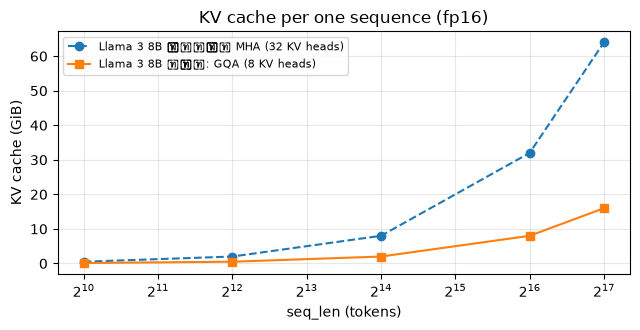

In [52]:
GiB = 2 ** 30


def kv_from_cfg(c, seq_len, mha=False, **kw):
    """mha=True: สมมติว่าไม่ใช้ GQA (KV heads = query heads)"""
    return kv_cache_bytes(c["layers"], c["heads"] if mha else c["kv_heads"], c["head_dim"], seq_len, **kw)


# 🔍 ตรวจคำตอบ 
L3 = CFG["meta-llama/Meta-Llama-3-8B"]
assert kv_from_cfg(L3, 1) == 128 * 1024                       # 128 KB ต่อโทเคน
assert kv_from_cfg(L3, 8192) == 1 * GiB                        # 8k โทเคน = 1 GiB
assert kv_from_cfg(L3, 8192, mha=True) == 4 * GiB              # ถ้าไม่ใช้ GQA = 4 GiB
assert kv_from_cfg(L3, 131072) == 16 * GiB
assert kv_cache_bytes(2, 2, 4, 3, batch=5, bytes_per_value=4) == 2 * 2 * 2 * 4 * 3 * 5 * 4
print("✅ TODO 11 ผ่าน\n")

for name in ["gpt2", "Qwen/Qwen3-0.6B", "meta-llama/Meta-Llama-3-8B"]:
    c = CFG[name]
    n = min(c["max_pos"], 32768)
    print(f"{name:<28s} {n:>6,} โทเคน: KV cache {kv_from_cfg(c, n) / GiB:6.2f} GiB "
          f"(ถ้าไม่ใช้ GQA {kv_from_cfg(c, n, mha=True) / GiB:6.2f} GiB)")

seq = np.array([1_024, 4_096, 16_384, 65_536, 131_072])
plt.figure(figsize=(6.5, 3.4))
plt.plot(seq, [kv_from_cfg(L3, s, mha=True) / GiB for s in seq], "o--", label="Llama 3 8B ถ้าเป็น MHA (32 KV heads)")
plt.plot(seq, [kv_from_cfg(L3, s) / GiB for s in seq], "s-", label="Llama 3 8B จริง: GQA (8 KV heads)")
plt.xscale("log", base=2); plt.xlabel("seq_len (tokens)"); plt.ylabel("KV cache (GiB)")
plt.title("KV cache per one sequence (fp16)"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**คำถามชวนคิด:** การ์ดจอ 24 GB โหลดน้ำหนัก Llama 3 8B แบบ fp16 (ราว 16 GB) แล้วจะเหลือที่ให้ KV cache เท่าไร
และรองรับผู้ใช้พร้อมกันกี่คน ถ้าแต่ละคนใช้ context 8,192 โทเคน? ถ้าโมเดลเป็น MHA ล่ะ?
(นี่คือเหตุผลที่ GQA, MLA, sliding window และ KV cache แบบ 8 บิต สำคัญมากในปี 2026)

---
# ส่วนที่ 4 — การประยุกต์: fine-tune ภาษาไทย และแปลภาษา

📖 สไลด์ 7-1 · 29–31 · SLP3 §9.4 หน้า 211–213 · Lee §15.7 หน้า 388–392

Mini-GPT ในส่วนที่ 1 เรียนจากศูนย์และรู้แค่ภาษาของเล่น ในงานจริงเราจะ **เริ่มจากโมเดลที่ pretrain มาแล้ว**
แล้วฝึกต่อกับงานเฉพาะด้วยข้อมูลไม่กี่พันตัวอย่าง — **transfer learning / fine-tuning**

```
[ pretrained encoder ]  ──►  เวกเตอร์ของโทเคนแรก (<s> / [CLS])  ──►  head ใหม่ (สุ่มค่าเริ่มต้น)  ──►  {pos, neu, neg}
   ฝึกต่อด้วย lr เล็ก (2e-5)                                            ฝึกตั้งแต่ศูนย์
```

| `TASK` | โมเดลตั้งต้น | ข้อมูล | หมายเหตุ |
|---|---|---|---|
| `"wisesight"` (ค่าเริ่มต้น) | **WangchanBERTa** (`airesearch/wangchanberta-base-att-spm-uncased`) | wisesight-sentiment 3 คลาส — **แบ่ง train/dev/test เหมือนแล็บ 5–6 Task 5** | ควรใช้ GPU |
| `"sst2"` (ทางสำรอง) | `distilbert-base-uncased` | SST-2 ภาษาอังกฤษ 2 คลาส | รันบน CPU ได้ |

ผลจากแล็บ 5–6 บน test ชุดเดียวกัน (2,617 ข้อความ): majority 55.64% · TF-IDF + LogReg **73.67%** (macro-F1 0.680) · LSTM 71.72% (macro-F1 0.640)

## 4.1 โหลดข้อมูล

In [53]:
import os
import re
import urllib.request
from datasets import Dataset, load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

TASK = "wisesight"            # 🎛️ หรือ "sst2"
ON_GPU = torch.cuda.is_available()

if TASK == "wisesight":
    BASE_NAME = "airesearch/wangchanberta-base-att-spm-uncased"
    LABELS = ["pos", "neu", "neg"]
    MAX_LEN = 128
    N_TRAIN = None if ON_GPU else 2000        # None = ใช้ train ทั้งหมด (20,929 ข้อความ)
    WS_URL = "https://raw.githubusercontent.com/PyThaiNLP/wisesight-sentiment/master/{}.txt"
    WS_DIR = os.path.join("data", "wisesight")

    def load_wisesight():
        """เหมือนแล็บ 5–6 ทุกบรรทัด (ลำดับไฟล์ pos, neu, neg) เพื่อให้ได้ split เดียวกัน"""
        os.makedirs(WS_DIR, exist_ok=True)
        texts, labels = [], []
        for lab in LABELS:
            path = os.path.join(WS_DIR, f"{lab}.txt")
            if not os.path.exists(path):
                urllib.request.urlretrieve(WS_URL.format(lab), path)
            with open(path, encoding="utf-8") as f:
                lines = [l.strip() for l in f if l.strip()]
            texts += lines
            labels += [lab] * len(lines)
        return texts, labels

    def wangchan_preprocess(t):
        """WangchanBERTa ฝึกด้วยข้อความตัวพิมพ์เล็ก และแทนช่องว่างด้วยโทเคน <_>"""
        return re.sub(r"\s+", " ", t.lower()).strip().replace(" ", "<_>")

    ws_texts, ws_labels = load_wisesight()
    ws_y = [LABELS.index(l) for l in ws_labels]
    idx_train, idx_rest = train_test_split(range(len(ws_y)), test_size=0.2, stratify=ws_y, random_state=SEED)
    idx_dev, idx_test = train_test_split(idx_rest, test_size=0.5, stratify=[ws_y[i] for i in idx_rest],
                                         random_state=SEED)
    mk = lambda idx: Dataset.from_dict({"sentence": [wangchan_preprocess(ws_texts[i]) for i in idx],
                                        "label": [ws_y[i] for i in idx]})
    train_raw, dev_raw, test_raw = mk(idx_train), mk(idx_dev), mk(idx_test)
    test_text = [ws_texts[i] for i in idx_test]                       # ข้อความดิบไว้ดูตอนวิเคราะห์ข้อผิดพลาด
    print(f"train {len(train_raw):,} | dev {len(dev_raw):,} | test {len(test_raw):,}")
    assert (len(train_raw), len(test_raw)) == (20929, 2617), "split ต้องตรงกับแล็บ 5–6"
else:
    BASE_NAME = "distilbert-base-uncased"
    LABELS = ["negative", "positive"]
    MAX_LEN = 64
    N_TRAIN = 2000
    raw = load_dataset("stanfordnlp/sst2")
    train_raw = raw["train"].shuffle(seed=SEED)
    test_raw = raw["validation"]               # ชุด test ของ GLUE ไม่มี label จึงใช้ validation เป็น test
    test_text = test_raw["sentence"]

if N_TRAIN is not None:
    train_raw = train_raw.shuffle(seed=SEED).select(range(N_TRAIN))
print(f"\nใช้ฝึก {len(train_raw):,} ตัวอย่าง · ตัวอย่างแรก:", train_raw[0])
print("สัดส่วนคลาสใน train:", np.bincount(train_raw["label"]) / len(train_raw))

train 20,929 | dev 2,616 | test 2,617

ใช้ฝึก 2,000 ตัวอย่าง · ตัวอย่างแรก: {'sentence': 'มีสาขาอิมสำโรงห่วยแตกสุด', 'label': 2}
สัดส่วนคลาสใน train: [0.177 0.546 0.277]


## 4.2 Tokenize

- `truncation=True, max_length=MAX_LEN` — ตัดข้อความที่ยาวเกิน
- **ยังไม่ pad** ตอนนี้ — ให้ `DataCollatorWithPadding` pad ทีละ batch ให้ยาวเท่าข้อความยาวสุดใน batch นั้น
  (**dynamic padding** เร็วกว่า pad ทุกข้อความให้ยาวเท่ากันมาก)

### ✏️ TODO 12 — ฟังก์ชัน tokenize สำหรับ `Dataset.map`

In [58]:
base_tok = AutoTokenizer.from_pretrained(BASE_NAME)


def tokenize_fn(batch):
    return base_tok(batch["sentence"], truncation=True, max_length=MAX_LEN)

In [59]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding


def prepare(ds):
    ds = ds.map(tokenize_fn, batched=True, remove_columns=[c for c in ds.column_names if c != "label"])
    return ds.rename_column("label", "labels")


train_ds, test_ds = prepare(train_raw), prepare(test_raw)
collator = DataCollatorWithPadding(base_tok)
BATCH = 32 if ON_GPU else 16
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, collate_fn=collator)
test_loader = DataLoader(test_ds, batch_size=64, collate_fn=collator)

batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items()})
print("ตัวอย่างโทเคน:", base_tok.convert_ids_to_tokens(train_ds[0]["input_ids"])[:20])

# 🔍 ตรวจคำตอบ
assert set(train_ds.column_names) == {"input_ids", "attention_mask", "labels"}
assert max(len(x) for x in train_ds["input_ids"]) <= MAX_LEN
print("✅ TODO 12 ผ่าน")

Map: 100%|██████████| 2617/2617 [00:00<00:00, 8322.80 examples/s]

{'labels': (16,), 'input_ids': (16, 99), 'attention_mask': (16, 99)}
ตัวอย่างโทเคน: ['<s>', '▁มี', 'สาขา', 'อิม', 'สําโรง', 'ห่วยแตก', 'สุด', '</s>']
✅ TODO 12 ผ่าน


## 4.3 โหลดโมเดลพร้อม classification head ใหม่

ไลบรารีจะเตือนว่า weight ของ head **ถูกสุ่มค่าเริ่มต้นใหม่** — เป็นเรื่องปกติ
เพราะ head นี้ไม่มีใน checkpoint ที่ pretrain ด้วย Masked LM ก่อน fine-tune โมเดลจึงเดาแบบสุ่ม

In [60]:
ID2LABEL = dict(enumerate(LABELS))
LABEL2ID = {v: k for k, v in ID2LABEL.items()}


def load_base_model():
    set_seed()
    return AutoModelForSequenceClassification.from_pretrained(
        BASE_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)


@torch.no_grad()
def predict_loader(model, loader=test_loader):
    model.eval()
    preds, golds = [], []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        preds += model(**batch).logits.argmax(-1).tolist()
        golds += batch["labels"].tolist()
    return np.array(preds), np.array(golds)


def evaluate_acc(model, loader=test_loader):
    p, g = predict_loader(model, loader)
    return float((p == g).mean())


def evaluate_f1(model, loader=test_loader):
    p, g = predict_loader(model, loader)
    return float((p == g).mean()), float(f1_score(g, p, average="macro"))


model_ft = load_base_model()
acc_before, f1_before = evaluate_f1(model_ft)
print(f"{BASE_NAME}: {sum(p.numel() for p in model_ft.parameters()) / 1e6:.1f} M พารามิเตอร์")
print(f"ก่อน fine-tune: accuracy {acc_before:.1%} · macro-F1 {f1_before:.3f}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1194.96it/s]


airesearch/wangchanberta-base-att-spm-uncased: 105.2 M พารามิเตอร์
ก่อน fine-tune: accuracy 35.8% · macro-F1 0.312


## 4.4 Fine-tune ด้วย training loop ของเราเอง

สูตรมาตรฐานสำหรับ fine-tune ตระกูล BERT (Devlin et al., 2019):
- **AdamW**, lr = 2e-5 ถึง 5e-5, weight decay 0.01
- **linear warmup** 10% แรก แล้ว **linear decay** จนเป็น 0 — กัน gradient ก้อนแรก ๆ จาก head ที่ยังสุ่มอยู่
  ไปทำลายน้ำหนักที่ pretrain มา (แนวคิดเดียวกับ warmup ในเปเปอร์ — สไลด์ 7-1 · 12)
- 2–4 epochs ก็พอ (มากกว่านี้มัก overfit)

**สังเกต:** เมื่อส่ง `labels` เข้าไปใน `model(**batch)` โมเดลจะคำนวณ cross-entropy ให้เองใน `out.loss`

### ✏️ TODO 13 — ฟังก์ชัน fine-tune

In [61]:
from transformers import get_linear_schedule_with_warmup


def finetune(model, loader=train_loader, epochs=2, lr=2e-5, warmup_ratio=0.1, clip=1.0):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    total_steps = epochs * len(loader)
    sched = get_linear_schedule_with_warmup(
        opt, num_warmup_steps=int(warmup_ratio * total_steps), num_training_steps=total_steps)

    losses = []
    for ep in range(1, epochs + 1):
        model.train()
        ep_losses = []
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            out = model(**batch)                                  # มี labels -> out.loss
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(params, clip)
            opt.step()
            sched.step()
            opt.zero_grad()
            losses.append(out.loss.item())
            ep_losses.append(out.loss.item())
        acc = evaluate_acc(model)
        print(f"epoch {ep}/{epochs} | loss {np.mean(ep_losses):.4f} | test acc {acc:.1%}")
    return losses

In [62]:
EPOCHS = 2
losses_full = finetune(model_ft, epochs=EPOCHS, lr=2e-5 if TASK == "sst2" else 3e-5)
acc_full, f1_full = evaluate_f1(model_ft)

plt.figure(figsize=(6, 3))
plt.plot(np.convolve(losses_full, np.ones(20) / 20, mode="valid"))
plt.xlabel("step"); plt.ylabel("loss (moving avg 20)"); plt.title("Full fine-tuning")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# 🔍 ตรวจคำตอบ
assert acc_full > acc_before + 0.10, "หลัง fine-tune ควรดีขึ้นอย่างน้อย 10 จุด — ตรวจ finetune() อีกครั้ง"
print(f"✅ TODO 13 ผ่าน — accuracy {acc_before:.1%} → {acc_full:.1%} · macro-F1 {f1_full:.3f}")

epoch 1/2 | loss 0.9143 | test acc 66.3%


KeyboardInterrupt: 

## 4.5 Linear probe — แช่แข็ง encoder ฝึกแค่ head

ถ้า **ไม่แตะ** น้ำหนักของ Transformer เลย ฝึกเฉพาะ classification head จะได้ผลแค่ไหน?
การทดลองนี้บอกว่า representation ที่ pretrain มามีข้อมูลเรื่องความรู้สึกอยู่แล้วมากเพียงใด

### ✏️ TODO 14 — แช่แข็ง encoder

คำใบ้: `model.base_model` คือตัว encoder ไม่ว่าจะเป็น DistilBERT (`model.distilbert`) หรือ WangchanBERTa (`model.roberta`)

In [63]:
def freeze_encoder(model):
    for p in model.base_model.parameters():
        p.requires_grad = False
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

In [64]:
model_lp = load_base_model()
trainable, total = freeze_encoder(model_lp)
print(f"ฝึกได้ {trainable:,} จาก {total:,} พารามิเตอร์ ({trainable / total:.2%})")

# 🔍 ตรวจคำตอบ — ที่ฝึกได้ต้องเหลือแค่ head (dense 768×768 + ชั้นออก 768×จำนวนคลาส)
n_cls = len(LABELS)
assert trainable == 768 * 768 + 768 + 768 * n_cls + n_cls
print("✅ TODO 14 ผ่าน\n")

# head ใหม่ทั้งหมด จึงใช้ lr สูงกว่าได้
losses_lp = finetune(model_lp, epochs=EPOCHS, lr=1e-3)
acc_lp, f1_lp = evaluate_f1(model_lp)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1007.24it/s]


ฝึกได้ 592,899 จาก 105,246,723 พารามิเตอร์ (0.56%)
✅ TODO 14 ผ่าน



KeyboardInterrupt: 

In [65]:
print(f"{'วิธี':<34s}{'ฝึกได้':>14s}{'accuracy':>10s}{'macro-F1':>10s}")
print("-" * 68)
n_all = sum(p.numel() for p in model_ft.parameters())
if TASK == "wisesight":
    # ผลจากแล็บ 5–6 Task 5 บน test ชุดเดียวกัน
    print(f"{'แล็บ 5–6: majority':<34s}{'—':>14s}{0.5564:>10.1%}{0.238:>10.3f}")
    print(f"{'แล็บ 5–6: TF-IDF + LogReg':<34s}{'—':>14s}{0.7367:>10.1%}{0.680:>10.3f}")
    print(f"{'แล็บ 5–6: LSTM':<34s}{'—':>14s}{0.7172:>10.1%}{0.640:>10.3f}")
print(f"{'ไม่ fine-tune (head สุ่ม)':<34s}{0:>14,}{acc_before:>10.1%}{f1_before:>10.3f}")
print(f"{'Linear probe':<34s}{trainable:>14,}{acc_lp:>10.1%}{f1_lp:>10.3f}")
print(f"{'Full fine-tune':<34s}{n_all:>14,}{acc_full:>10.1%}{f1_full:>10.3f}")

วิธี                                      ฝึกได้  accuracy  macro-F1
--------------------------------------------------------------------
แล็บ 5–6: majority                             —     55.6%     0.238
แล็บ 5–6: TF-IDF + LogReg                      —     73.7%     0.680
แล็บ 5–6: LSTM                                 —     71.7%     0.640
ไม่ fine-tune (head สุ่ม)                      0     35.8%     0.312


NameError: name 'acc_lp' is not defined

**คำถามชวนคิด:** Transformer ที่ pretrain มาชนะ TF-IDF ของแล็บ 5–6 มากแค่ไหน คุ้มกับเวลาฝึกและขนาดโมเดลหรือไม่?
linear probe อยู่ตรงไหนเมื่อเทียบกับ TF-IDF — บอกอะไรเกี่ยวกับ representation ของ WangchanBERTa?

## 4.6 Encoder–decoder: แปลไทย → อังกฤษ และวัดด้วย chrF

📖 สไลด์ 7-1 · 20 (สามตระกูล) และ 30 · สัปดาห์ 6: chrF — SLP3 eq 12.20 หน้า 277

ตระกูลที่สามคือ **encoder–decoder** แบบเปเปอร์ต้นฉบับ — เหมาะกับงานที่แปลงลำดับหนึ่งเป็นอีกลำดับ
เราจะใช้ `Helsinki-NLP/opus-mt-th-en` (MarianMT = Transformer encoder–decoder แบบเปเปอร์ ฝึกบนคลัง OPUS) แปลประโยคไทยสั้น ๆ แล้ววัดด้วย **chrF**
(เรียก `model.generate` ตรง ๆ แทน `pipeline` เพราะ transformers รุ่น 5 เลิกมี pipeline งานแปลแล้ว)

$$\text{chrP} = \frac{1}{N}\sum_{n=1}^{N}\frac{\#\text{n-gram อักษรที่ตรงกัน}}{\#\text{n-gram ในคำแปล}},\quad
\text{chrR} = \frac{1}{N}\sum_{n=1}^{N}\frac{\#\text{ตรงกัน}}{\#\text{n-gram ในเฉลย}},\quad
\text{chrF}_\beta = \frac{(1+\beta^2)\,\text{chrP}\cdot\text{chrR}}{\beta^2\,\text{chrP} + \text{chrR}}$$

ใช้ N = 6, β = 2 (ให้น้ำหนัก recall มากกว่า) · **ตัดช่องว่างทิ้งก่อนนับ** · ระดับคลังข้อความ: รวมจำนวนนับทุกประโยคก่อนหาร

### ✏️ TODO 15 — `chrf`

In [70]:
def char_ngrams(s, n):
    """Counter ของ n-gram ตัวอักษร หลังลบช่องว่าง"""
    s = s.replace(" ", "")
    return Counter(s[i:i + n] for i in range(len(s) - n + 1))


def chrf(hyps, refs, n_max=6, beta=2.0):
    precisions, recalls = [], []
    for n in range(1, n_max + 1):
        match = h_total = r_total = 0
        for h, r in zip(hyps, refs):
            hc, rc = char_ngrams(h, n), char_ngrams(r, n)
            match += sum((hc & rc).values())      # จำนวน n-gram ที่ตรงกัน (นับแบบ clipped)
            h_total += sum(hc.values())
            r_total += sum(rc.values())
        if h_total > 0 and r_total > 0:           # ใช้เฉพาะ n ที่ทั้งสองฝั่งมี n-gram
            precisions.append(match / h_total)
            recalls.append(match / r_total)

    if not precisions:
        return 0.0
    P = sum(precisions) / len(precisions)
    R = sum(recalls) / len(recalls)
    if P + R == 0:
        return 0.0
    b2 = beta ** 2
    return 100 * (1 + b2) * P * R / (b2 * P + R)

In [71]:
# 🔍 ตรวจคำตอบ
_refs = ["I like to eat sticky rice with mango.", "The weather is very hot today.",
         "My mother goes to the market every morning.", "This restaurant is cheap but delicious.",
         "Please close the door when you leave."]
_hyps = ["I like eating mango sticky rice.", "Today the weather is very hot.", "Mother goes to market every morning.",
         "This shop is cheap but tasty.", "Please shut the door when leaving."]
assert abs(chrf(_refs, _refs) - 100) < 1e-9
assert chrf(["xyz"], ["abc"]) == 0.0
assert abs(chrf(_hyps, _refs) - 57.5488) < 1e-3, chrf(_hyps, _refs)
try:                                    # ถ้ามี sacrebleu ให้เทียบด้วย
    import sacrebleu
    assert abs(chrf(_hyps, _refs) - sacrebleu.corpus_chrf(_hyps, [_refs]).score) < 1e-6
    print("ตรงกับ sacrebleu ✔")
except ImportError:
    pass
print(f"chrF ตัวอย่าง = {chrf(_hyps, _refs):.2f}")
print("✅ TODO 15 ผ่าน")

ตรงกับ sacrebleu ✔
chrF ตัวอย่าง = 57.55
✅ TODO 15 ผ่าน


In [72]:
# ประโยคทดสอบไทย–อังกฤษ (ผู้สอนแต่งขึ้น ใช้ในชั้นเรียนได้)
MT_PAIRS = [
    ("ฉันชอบกินข้าวเหนียวมะม่วง", "I like to eat mango sticky rice."),
    ("วันนี้อากาศร้อนมาก", "The weather is very hot today."),
    ("แม่ไปตลาดทุกเช้า", "My mother goes to the market every morning."),
    ("ร้านนี้ราคาถูกแต่อร่อย", "This restaurant is cheap but delicious."),
    ("กรุณาปิดประตูเมื่อออกจากห้อง", "Please close the door when you leave the room."),
    ("นักเรียนกำลังอ่านหนังสือในห้องสมุด", "The students are reading books in the library."),
    ("รถไฟฟ้ามาช้ากว่าปกติสิบนาที", "The train arrived ten minutes later than usual."),
    ("เขาเรียนภาษาญี่ปุ่นมาสามปีแล้ว", "He has been studying Japanese for three years."),
    ("พรุ่งนี้เราจะไปเที่ยวทะเลกัน", "Tomorrow we will go to the beach."),
    ("โทรศัพท์ของฉันแบตหมด", "My phone's battery is dead."),
    ("อาจารย์ให้การบ้านเยอะมาก", "The teacher gave us a lot of homework."),
    ("ช่วยพูดช้าลงหน่อยได้ไหม", "Could you speak a little more slowly?"),
]
from transformers import AutoModelForSeq2SeqLM

MT_NAME = "Helsinki-NLP/opus-mt-th-en"
mt_tok = AutoTokenizer.from_pretrained(MT_NAME)
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_NAME).to(DEVICE).eval()
mc = mt_model.config
print(f"{MT_NAME}: encoder {mc.encoder_layers} ชั้น + decoder {mc.decoder_layers} ชั้น · d_model {mc.d_model} · "
      f"{mc.encoder_attention_heads} หัว · {sum(p.numel() for p in mt_model.parameters()) / 1e6:.0f} M พารามิเตอร์\n")


@torch.no_grad()
def translate(texts, num_beams=1, max_new_tokens=64):
    """encoder อ่านประโยคไทยทั้งประโยค → decoder สร้างคำอังกฤษทีละโทเคน (cross-attention ไปที่ encoder)"""
    enc = mt_tok(texts, return_tensors="pt", padding=True).to(DEVICE)
    out = mt_model.generate(**enc, num_beams=num_beams, max_new_tokens=max_new_tokens)
    return mt_tok.batch_decode(out, skip_special_tokens=True)


src = [s for s, _ in MT_PAIRS]
refs = [r for _, r in MT_PAIRS]
hyp_greedy = translate(src, num_beams=1)
hyp_beam = translate(src, num_beams=4)          # beam 4 แบบเปเปอร์ (สัปดาห์ 6)
for s, r, g, b in zip(src, refs, hyp_greedy, hyp_beam):
    print(f"{s}\n   เฉลย  : {r}\n   greedy: {g}\n   beam 4: {b}\n")
print(f"chrF greedy = {chrf(hyp_greedy, refs):.1f} · chrF beam 4 = {chrf(hyp_beam, refs):.1f}")

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--Helsinki-NLP--opus-mt-th-en. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


KeyboardInterrupt: 

**คำถามชวนคิด:** ประโยคไหนที่ chrF ต่ำแต่คำแปลยังถูกความหมาย? (เช่น ใช้คำพ้องความหมาย หรือเรียงคำต่างจากเฉลย)
— นี่คือข้อจำกัดของตัววัดที่นับตัวอักษรตรงกัน และเหตุผลที่ควรมีเฉลยหลายฉบับ (สัปดาห์ 6)

> ทางเลือก: `facebook/nllb-200-distilled-600M` (ใช้ `src_lang="tha_Thai", tgt_lang="eng_Latn"`) แปลได้ 200 ภาษา แต่ใหญ่กว่าและเป็นสัญญาอนุญาตแบบไม่ใช้เชิงพาณิชย์

## 4.7 (ทางเลือก) ใช้ `Trainer` API

ในงานจริงนิยมใช้ `Trainer` ซึ่งรวม loop, scheduler, mixed precision, การ log และ checkpoint ไว้ให้
ตั้ง `RUN_TRAINER = True` เพื่อทดลอง (ต้องติดตั้ง `accelerate`)

In [73]:
RUN_TRAINER = False

if RUN_TRAINER:
    from transformers import Trainer, TrainingArguments

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        return {"accuracy": (logits.argmax(-1) == labels).mean()}

    args = TrainingArguments(
        output_dir="lab07_trainer_out", num_train_epochs=EPOCHS, learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=64,
        warmup_ratio=0.1, weight_decay=0.01, eval_strategy="epoch",
        save_strategy="no", logging_steps=25, report_to="none", seed=SEED)
    trainer = Trainer(model=load_base_model(), args=args, train_dataset=train_ds,
                      eval_dataset=test_ds, data_collator=collator, compute_metrics=compute_metrics)
    trainer.train()
    print(trainer.evaluate())

## 4.8 บันทึก โหลดกลับ และใช้งานโมเดลที่ fine-tune แล้ว

`save_pretrained` บันทึกทั้ง config และน้ำหนัก — โหลดกลับด้วย `from_pretrained` หรือส่ง path ให้ `pipeline` ได้เลย
(และอัปโหลดขึ้น Hugging Face Hub ได้ด้วย `push_to_hub`)

In [74]:
SAVE_DIR = f"lab07_{TASK}_finetuned"
model_ft.save_pretrained(SAVE_DIR)
base_tok.save_pretrained(SAVE_DIR)

my_clf = pipeline("text-classification", model=SAVE_DIR, device=DEVICE)
if TASK == "wisesight":
    demo = ["ร้านนี้อร่อยมาก บริการดีสุด ๆ จะมาอีกแน่นอน", "รอนานมาก อาหารเย็นชืด ไม่ประทับใจเลย",
            "พรุ่งนี้ร้านเปิดกี่โมงคะ"]
    demo_in = [wangchan_preprocess(t) for t in demo]
else:
    demo = ["An absolute masterpiece with a moving story.", "I want those two hours of my life back.",
            "The acting was fine but the plot made no sense."]
    demo_in = demo
for t, r in zip(demo, my_clf(demo_in)):
    print(f"{r['label']:>9s} {r['score']:.3f} | {t}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 732.12it/s]


      pos 0.505 | ร้านนี้อร่อยมาก บริการดีสุด ๆ จะมาอีกแน่นอน
      neg 0.849 | รอนานมาก อาหารเย็นชืด ไม่ประทับใจเลย
      neu 0.768 | พรุ่งนี้ร้านเปิดกี่โมงคะ


### วิเคราะห์ข้อผิดพลาด (Error analysis)

In [75]:
@torch.no_grad()
def show_errors(model, k=10):
    p_all, g_all = predict_loader(model)
    conf_all = []
    model.eval()
    for batch in test_loader:
        batch = {kk: v.to(DEVICE) for kk, v in batch.items()}
        conf_all += model(**batch).logits.softmax(-1).max(-1).values.tolist()
    errs = [(c, ID2LABEL[g], ID2LABEL[p], t) for c, g, p, t in zip(conf_all, g_all, p_all, test_text) if g != p]
    errs.sort(reverse=True)
    print(f"ผิดทั้งหมด {len(errs)} จาก {len(g_all)} ข้อความ — {k} ข้อความที่โมเดล 'มั่นใจแต่ผิด' มากที่สุด:\n")
    for conf, gold, pred, s in errs[:k]:
        print(f"[gold={gold:>8s} pred={pred:>8s} conf={conf:.2f}] {s[:120]}")


show_errors(model_ft)

KeyboardInterrupt: 

**คำถามชวนคิด:** ข้อความที่ผิดมีลักษณะร่วมกันอย่างไร? (การประชด, ข้อความที่มีทั้งชมและติ, คำถามที่ติดป้าย neu,
ภาษาโซเชียล/คำสะกดผิด) — เทียบกับข้อผิดพลาดของ TF-IDF ในแล็บ 5–6 แล้ว Transformer แก้ปัญหาแบบไหนได้ แบบไหนยังไม่ได้?

---
# 📊 สรุป Lab

In [76]:
print("ส่วนที่ 1 — Mini-GPT (ฝึกเองตั้งแต่ศูนย์)")
print(f"  val perplexity            : {math.exp(history[-1][2]):.2f}")
print(f"  ลักษณนาม: trigram          : {tri_acc:.1%}")
print(f"  ลักษณนาม: Mini-GPT         : {acc:.1%}")
print()
print("ส่วนที่ 2 — จำนวนโทเคนของ", repr(th))
for name, n in tok_counts.items():
    print(f"  {name.split('/')[-1]:<42s}: {n}")
print()
print("ส่วนที่ 3 — KV cache ของ Llama 3 8B ที่ 8,192 โทเคน")
print(f"  GQA (จริง) {kv_from_cfg(L3, 8192) / GiB:.0f} GiB · ถ้าเป็น MHA {kv_from_cfg(L3, 8192, mha=True) / GiB:.0f} GiB")
print()
print(f"ส่วนที่ 4 — {BASE_NAME} บน {TASK} (train {len(train_raw):,} ตัวอย่าง)")
print(f"  ไม่ fine-tune              : {acc_before:.1%}")
print(f"  linear probe              : {acc_lp:.1%}  (macro-F1 {f1_lp:.3f})")
print(f"  full fine-tune            : {acc_full:.1%}  (macro-F1 {f1_full:.3f})")
print(f"  แปลไทย→อังกฤษ chrF        : greedy {chrf(hyp_greedy, refs):.1f} · beam 4 {chrf(hyp_beam, refs):.1f}")

ส่วนที่ 1 — Mini-GPT (ฝึกเองตั้งแต่ศูนย์)
  val perplexity            : 6.14
  ลักษณนาม: trigram          : 40.6%
  ลักษณนาม: Mini-GPT         : 100.0%

ส่วนที่ 2 — จำนวนโทเคนของ 'ฉันชอบเรียนการประมวลผลภาษาธรรมชาติ'
  distilbert-base-uncased-finetuned-sst-2-english: 1
  gpt2                                      : 68
  xlm-roberta-base                          : 9
  wangchanberta-base-att-spm-uncased        : 6

ส่วนที่ 3 — KV cache ของ Llama 3 8B ที่ 8,192 โทเคน
  GQA (จริง) 1 GiB · ถ้าเป็น MHA 4 GiB

ส่วนที่ 4 — airesearch/wangchanberta-base-att-spm-uncased บน wisesight (train 2,000 ตัวอย่าง)
  ไม่ fine-tune              : 35.8%


NameError: name 'acc_lp' is not defined